In [1]:
import numpy as np
from skimage import io
import matplotlib.pyplot as plt

(1254, 1254)
[[253.     254.     253.9279 ... 254.9279 254.     254.    ]
 [253.7154 254.     253.0721 ... 254.     254.0721 254.0721]
 [253.     253.7875 253.7875 ... 254.     254.0721 254.0721]
 ...
 [253.1442 254.0721 254.0721 ... 254.     254.     254.    ]
 [253.0721 254.     254.     ... 254.     253.9279 253.9279]
 [252.     253.     253.     ... 253.     253.     252.    ]]


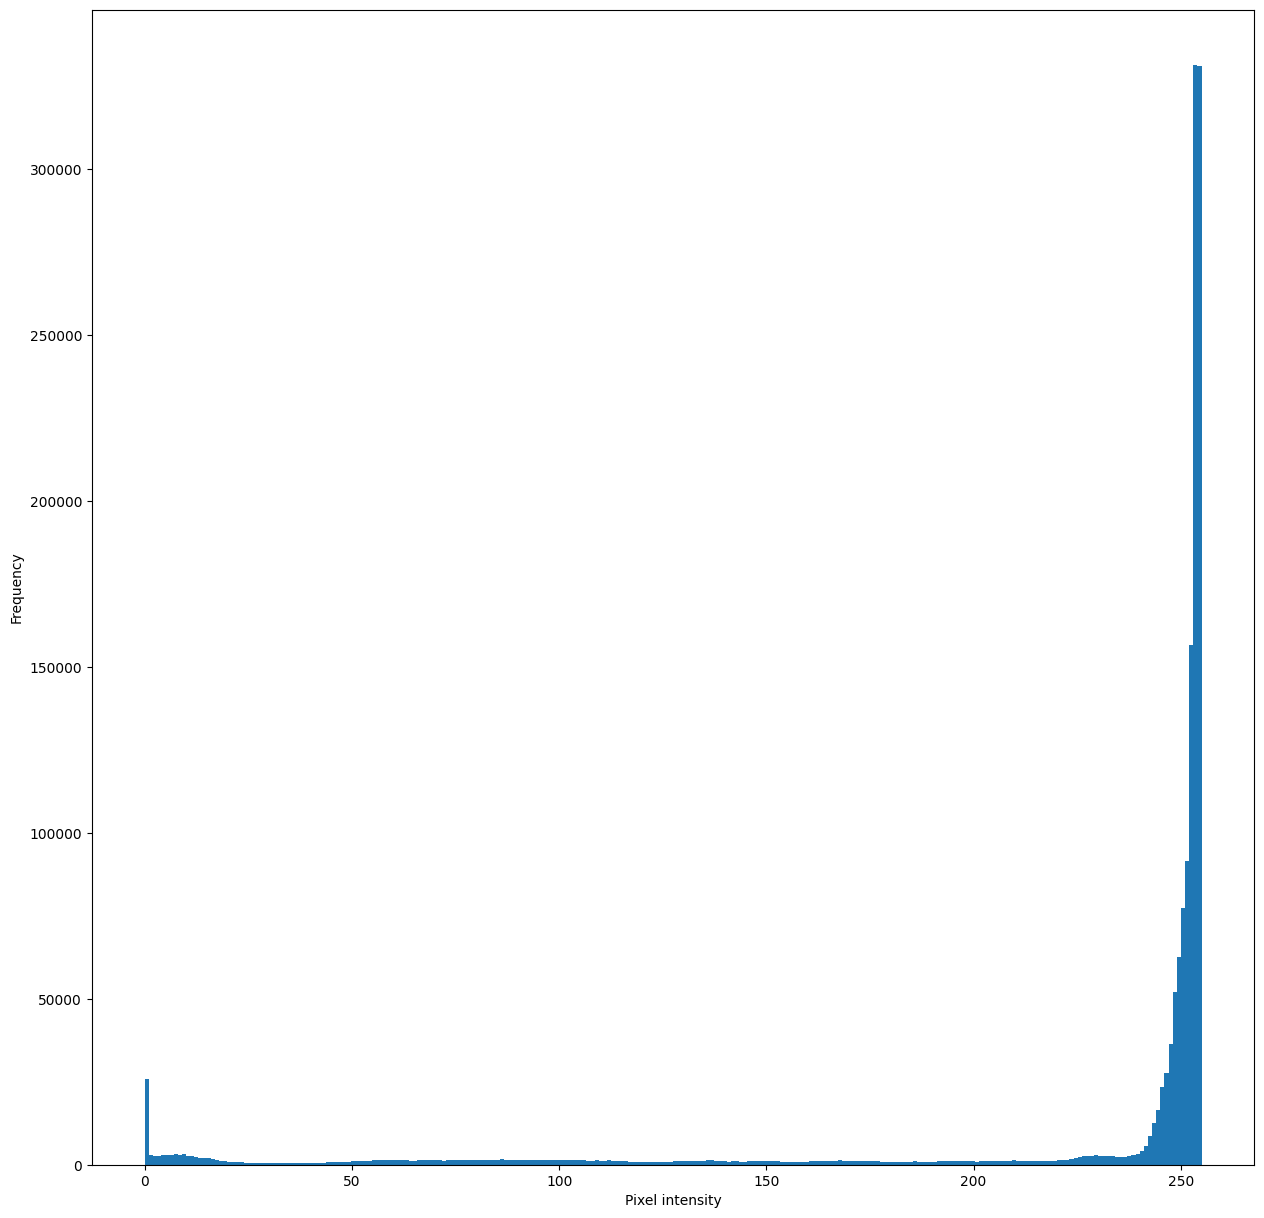

/tmp/ipykernel_3880141/2879268036.py:21: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  io.imshow(station[:,:].astype(np.uint8))


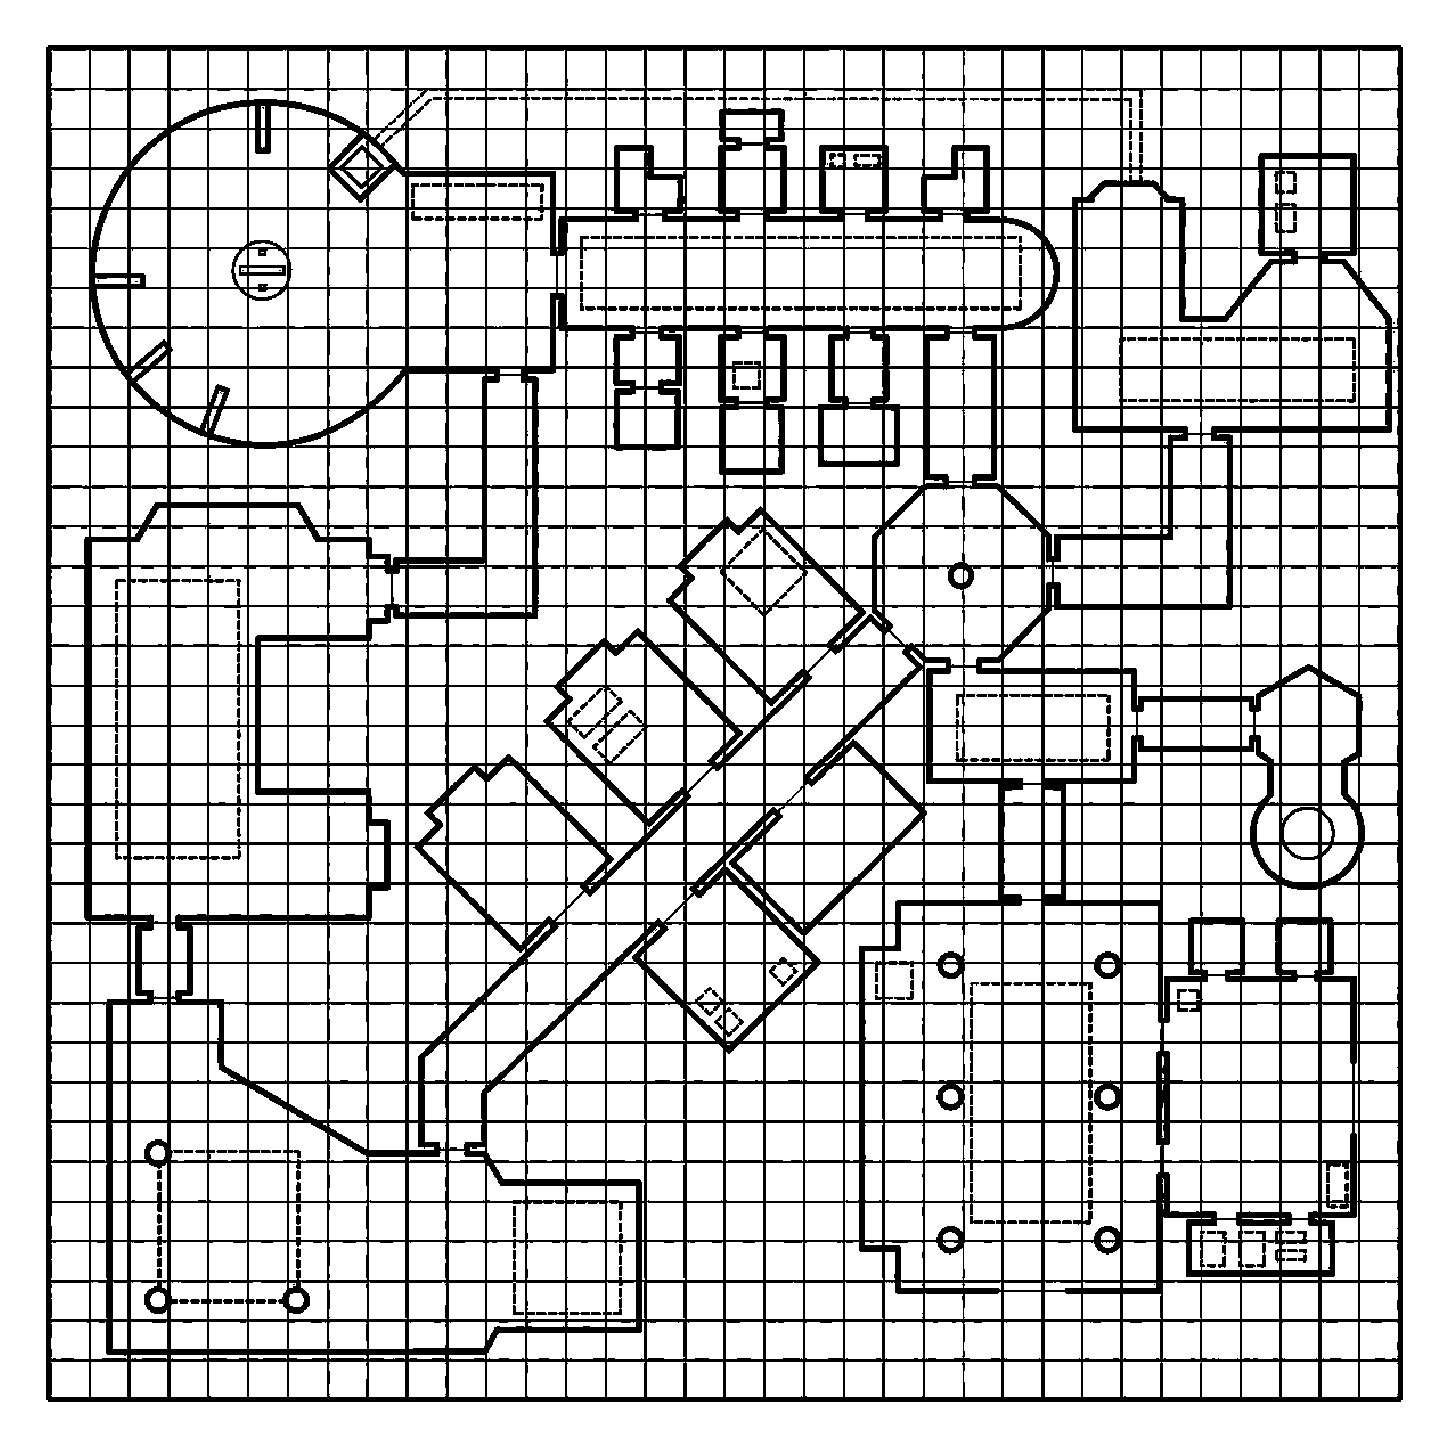

In [17]:

station = io.imread("chat-generated-map.png", as_gray=True).astype(np.float32)
station = station*255
print(station.shape)
print(station)



plt.figure(figsize=(15,15))
plt.hist(station[:,:].ravel(), bins=256)
plt.xlabel("Pixel intensity")
plt.ylabel("Frequency")
plt.show()

thresh = 230
station[station < thresh] = 0
station[station >= thresh] = 255


plt.figure(figsize=(15,15))

io.imshow(station[:,:].astype(np.uint8))
plt.axis('off')
plt.savefig("chat-binarised.png", dpi=300)
plt.show()



(2251, 2250, 2)


/tmp/ipykernel_3843082/517261898.py:6: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  io.imshow(station[:,:,0].astype(np.uint8))


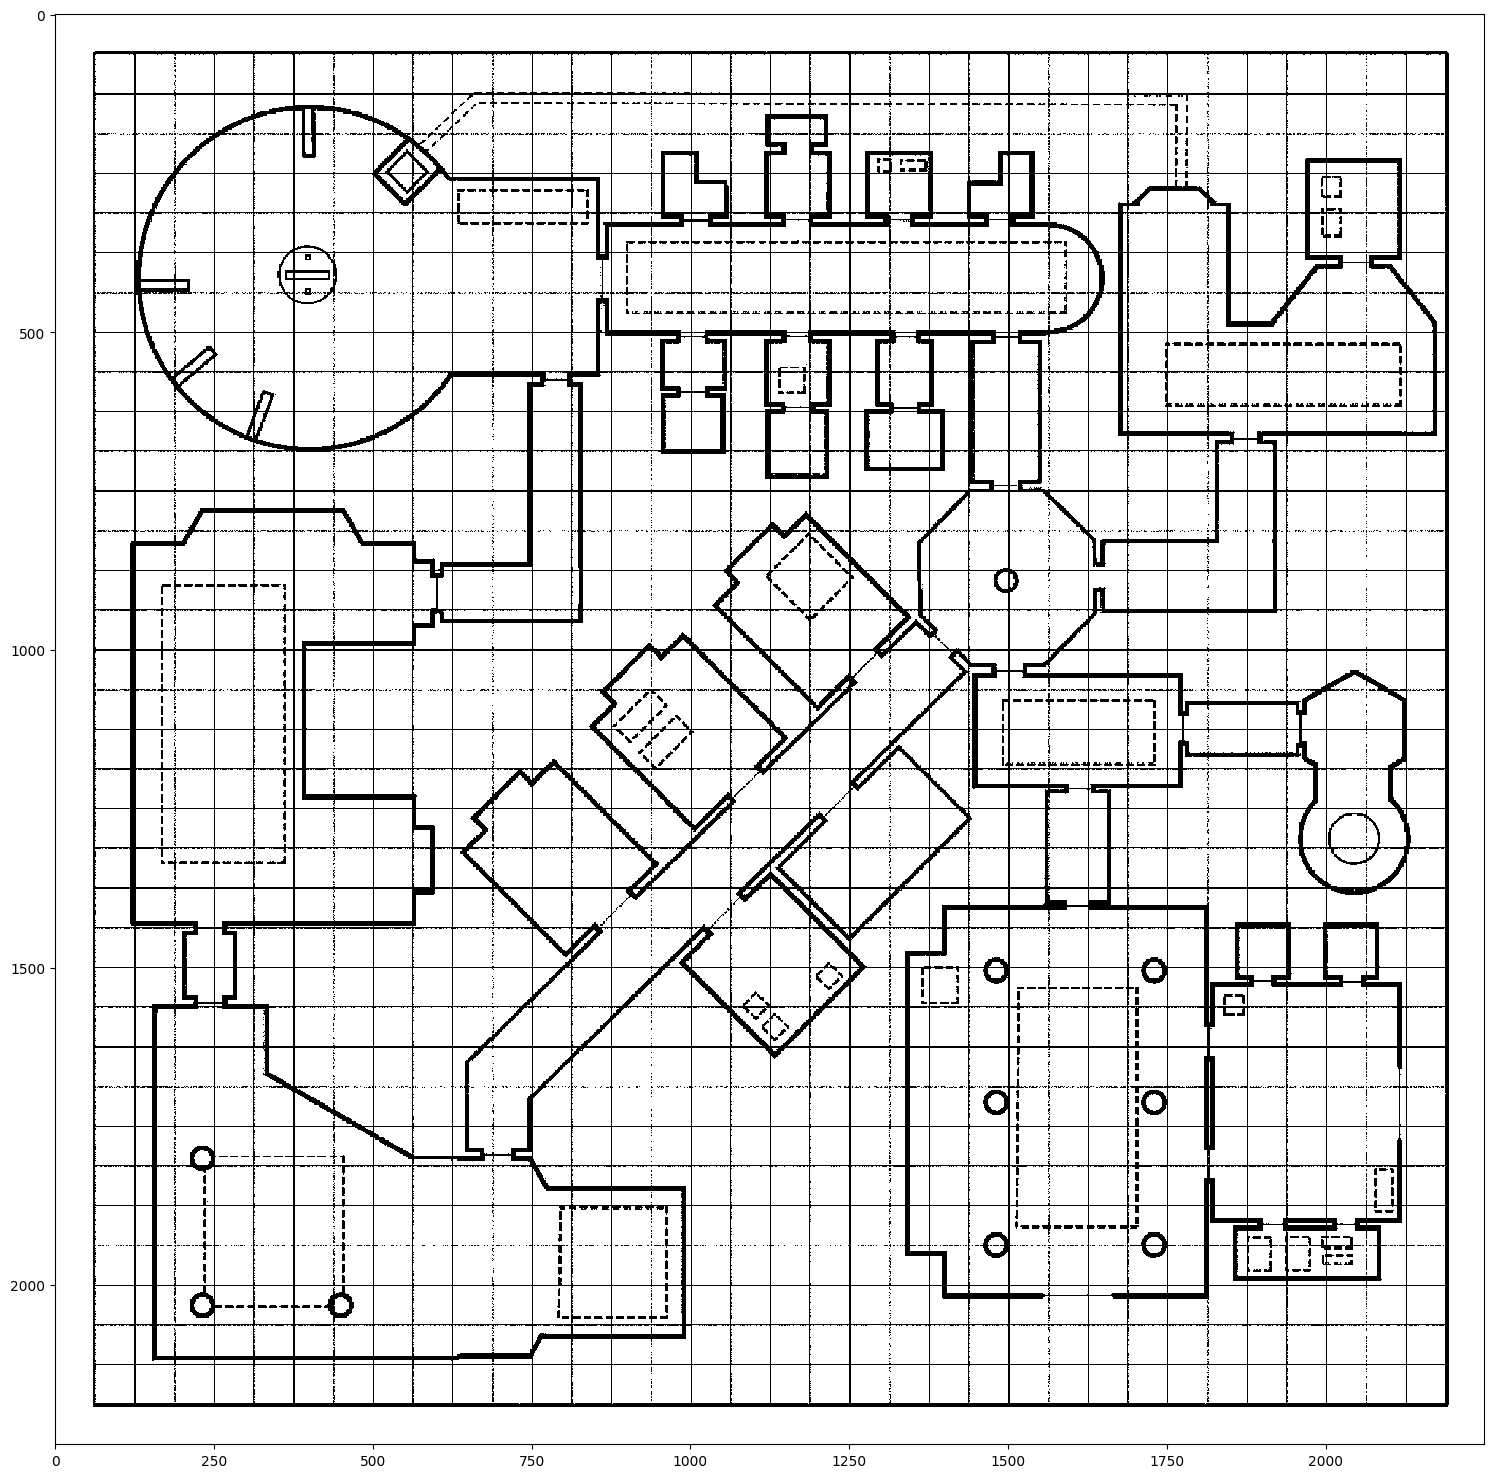

In [2]:

station = io.imread("Armaros station.png").astype(np.float32)
print(station.shape)

plt.figure(figsize=(15,15))

io.imshow(station[:,:,0].astype(np.uint8))


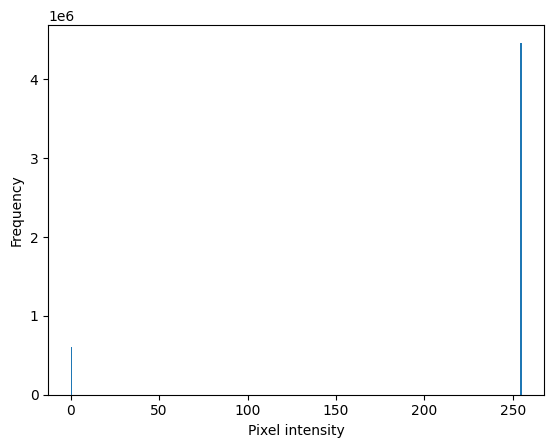

In [3]:
plt.hist(station[:,:,0].ravel(), bins=256)
plt.xlabel("Pixel intensity")
plt.ylabel("Frequency")
plt.show()

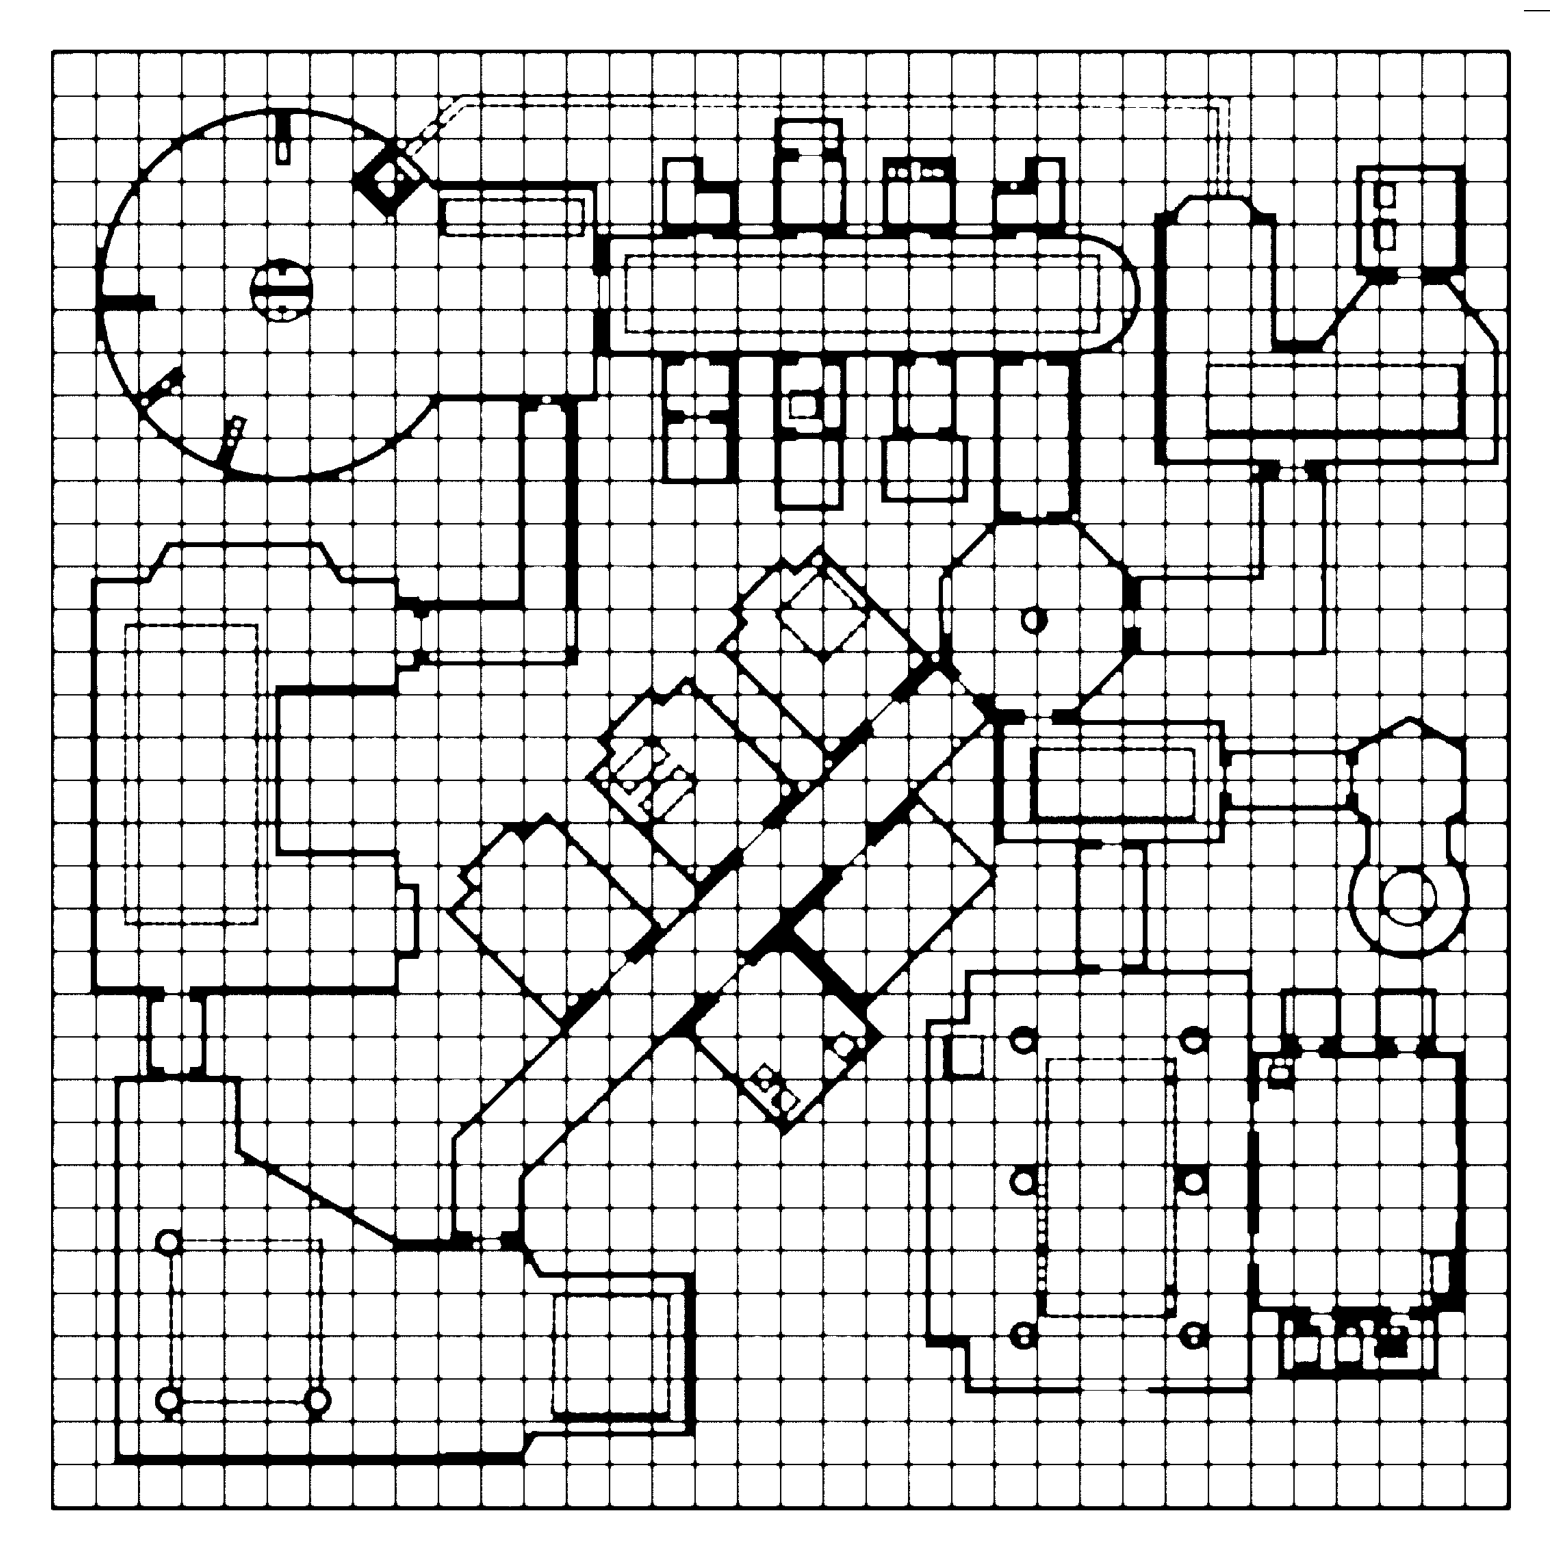

In [25]:
from skimage.morphology import dilation, disk, erosion, opening, closing
from skimage.morphology import thin

import matplotlib.pyplot as plt
station = io.imread("Armaros station (original).png").astype(np.float32)


dilated = opening(station[:,:,0], footprint=disk(5))
# thinner = thin(dilated, max_num_iter=1)


plt.figure(figsize=(20, 20))
# plt.subplot(1, 2, 1)
# plt.imshow(station[:,:,0], cmap='gray')
# plt.title("Original")

# plt.subplot(1, 2, 2)
plt.imshow(dilated, cmap='gray')
plt.axis("off")
# plt.title("Eroded")
plt.savefig('opened-map-shane.png',dpi=300, bbox_inches='tight')
plt.show()

## Detect gridlines

Grid spacing: 30 × 62 pixels


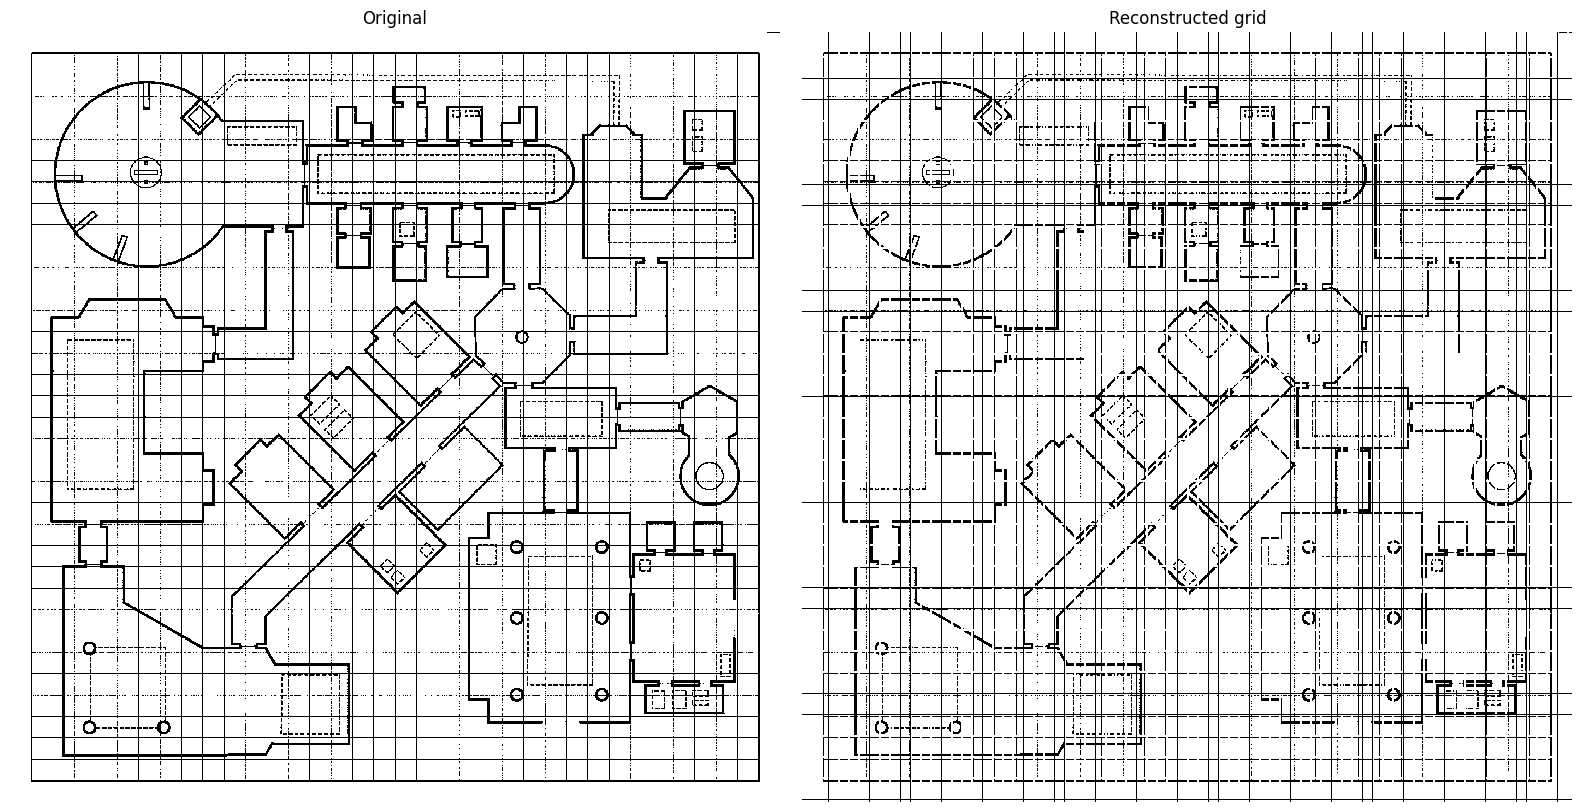

In [24]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
from PIL import Image

# Original binary image
img = station[:, :, 0] if station.ndim == 3 else station
binary = img > (127 if img.max() > 1 else 0.5)

H, W = binary.shape
ink = (~binary).astype(np.uint8)

# ---------------------------------------------------
# 1. Detect grid positions
# ---------------------------------------------------

# Grid lines repeat regularly, so use smoothed projections
row_profile = gaussian_filter1d(ink.mean(axis=1), sigma=1)
col_profile = gaussian_filter1d(ink.mean(axis=0), sigma=1)

rows, _ = find_peaks(row_profile, distance=20, prominence=0.015)
cols, _ = find_peaks(col_profile, distance=20, prominence=0.015)

# Estimate spacing using the most common peak difference
def estimate_spacing(positions):
    differences = np.diff(positions)
    differences = differences[differences > 10]
    if len(differences) == 0:
        raise ValueError("Could not estimate grid spacing.")
    counts = np.bincount(differences)
    return np.argmax(counts)

dy = estimate_spacing(rows)
dx = estimate_spacing(cols)

# Fit a regular grid phase to detected positions
def regular_grid(positions, spacing, limit):
    candidates = np.arange(spacing)
    scores = [
        np.mean(np.minimum(
            np.abs((positions - p) % spacing),
            spacing - np.abs((positions - p) % spacing)
        ))
        for p in candidates
    ]
    phase = int(np.argmin(scores))
    return np.arange(phase, limit, spacing)

grid_rows = regular_grid(rows, dy, H)
grid_cols = regular_grid(cols, dx, W)

print(f"Grid spacing: {dx} × {dy} pixels")

# ---------------------------------------------------
# 2. Remove old grid pixels
# ---------------------------------------------------

# Restrict removal to narrow strips around grid lines.
# NOTE: This can also erase parts of walls crossing the grid.
removal_radius = 2

clean = ink.copy()

for y in grid_rows:
    y0, y1 = max(0, y-removal_radius), min(H, y+removal_radius+1)
    clean[y0:y1, :] = 0

for x in grid_cols:
    x0, x1 = max(0, x-removal_radius), min(W, x+removal_radius+1)
    clean[:, x0:x1] = 0

# ---------------------------------------------------
# 3. Draw perfectly straight replacement grid
# ---------------------------------------------------

# 1-pixel-wide lines at the original resolution
for y in grid_rows:
    clean[y, :] = 1

for x in grid_cols:
    clean[:, x] = 1

# ---------------------------------------------------
# 4. Save and visualise
# ---------------------------------------------------

result = (1 - clean) * 255
result = result.astype(np.uint8)

Image.fromarray(result).save("station_clean_grid.png")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(binary, cmap="gray", interpolation="nearest")
axes[0].set_title("Original")

axes[1].imshow(result, cmap="gray", interpolation="nearest")
axes[1].set_title("Reconstructed grid")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
import cv2
import matplotlib.pyplot as plt

img = station[:, :, 0]

scale = 1

upscaled = cv2.resize(
    img,
    None,
    fx=scale,
    fy=scale,
    interpolation=cv2.INTER_LANCZOS4
)

plt.figure(figsize=(12, 12))
plt.imshow(upscaled, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.savefig('map-interp.png')
plt.show()

ModuleNotFoundError: No module named 'cv2'

# TV regularised inverse problem

Step    0 | Data: 0.002530 | TV: 0.022276 | Binary: 0.013516
Step  250 | Data: 0.001431 | TV: 0.022379 | Binary: 0.011753
Step  500 | Data: 0.000950 | TV: 0.022362 | Binary: 0.010376
Step  750 | Data: 0.000697 | TV: 0.022330 | Binary: 0.009350
Step 1000 | Data: 0.000545 | TV: 0.022303 | Binary: 0.008570
Step 1250 | Data: 0.000445 | TV: 0.022283 | Binary: 0.007958
Step 1499 | Data: 0.000375 | TV: 0.022271 | Binary: 0.007468


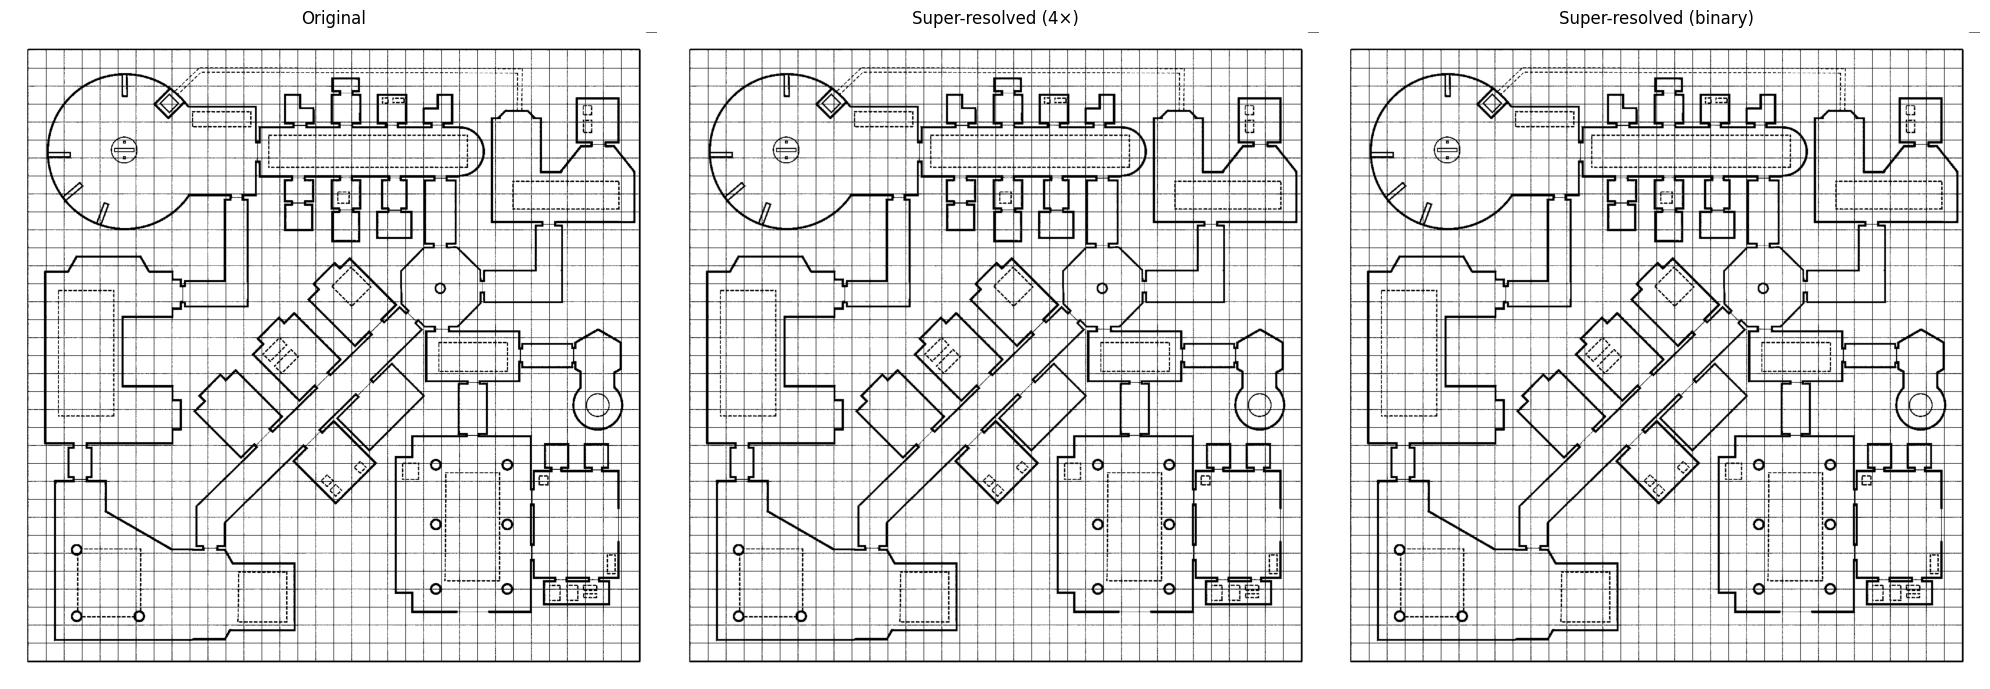

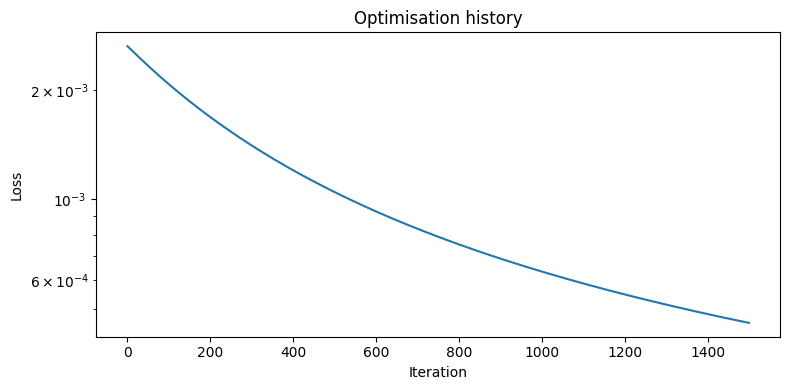

In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image


def superresolve_lines(
    image,
    scale=4,
    steps=1500,
    lr=0.03,
    lambda_tv=0.002,
    lambda_binary=0.005,
    device=None,
):
    """
    Optimisation-based super-resolution for binary line drawings.

    Parameters
    ----------
    image : ndarray, shape (H, W)
        Binary image, black lines on white background (0/1 or 0/255).
    scale : int
        Upscaling factor.
    steps : int
        Number of optimisation iterations.
    lr : float
        Learning rate.
    lambda_tv : float
        Total variation regularisation strength.
    lambda_binary : float
        Binary-image regularisation strength.

    Returns
    -------
    result : ndarray
        High-resolution grayscale reconstruction in [0, 1].
    losses : list
        Optimisation loss history.
    """

    if device is None:
        device = (
            "cuda" if torch.cuda.is_available()
            else "mps" if torch.backends.mps.is_available()
            else "cpu"
        )

    image = np.asarray(image, dtype=np.float32)

    if image.max() > 1:
        image /= 255.0

    y = torch.tensor(image, device=device)[None, None]
    H, W = image.shape

    # Initialise with bicubic interpolation
    x_init = F.interpolate(
        y,
        size=(H * scale, W * scale),
        mode="bicubic",
        align_corners=False,
    ).clamp(0.001, 0.999)
    # x_init = F.interpolate(
    #     y.cpu(),
    #     size=(H * scale, W * scale),
    #     mode="bicubic",
    #     align_corners=False,
    # ).clamp(0.001, 0.999).to(device)

    # Optimise logits to keep pixel values in [0, 1]
    z = torch.nn.Parameter(torch.logit(x_init))
    optimizer = torch.optim.Adam([z], lr=lr)

    losses = []

    for step in range(steps):
        optimizer.zero_grad()

        x = torch.sigmoid(z)

        # Forward model: downsample reconstructed image
        y_pred = F.interpolate(
            x,
            size=(H, W),
            mode="area",
        )

        # Data fidelity
        loss_data = F.mse_loss(y_pred, y)

        # Total variation regularisation
        tv_h = torch.abs(x[:, :, 1:, :] - x[:, :, :-1, :]).mean()
        tv_w = torch.abs(x[:, :, :, 1:] - x[:, :, :, :-1]).mean()
        loss_tv = tv_h + tv_w

        # Encourage binary pixel values
        loss_binary = (x * (1 - x)).mean()

        loss = (
            loss_data
            + lambda_tv * loss_tv
            + lambda_binary * loss_binary
        )

        loss.backward()
        optimizer.step()

        losses.append(loss.item())

        if step % 250 == 0 or step == steps - 1:
            print(
                f"Step {step:4d} | "
                f"Data: {loss_data.item():.6f} | "
                f"TV: {loss_tv.item():.6f} | "
                f"Binary: {loss_binary.item():.6f}"
            )

    result = torch.sigmoid(z).detach().cpu().numpy()[0, 0]

    return result, losses


# ============================================================
# Apply super-resolution
# ============================================================

# Input: existing image array, shape (H, W, C) or (H, W)
image = station[:, :, 0] if station.ndim == 3 else station

# Convert to binary
threshold = 0.5 if np.max(image) <= 1 else 127
binary = (image > threshold).astype(np.float32)

# Reconstruct at 4x resolution
result, losses = superresolve_lines(
    binary,
    scale=4,
    steps=1500,
    lr=0.03,
    lambda_tv=0.002,
    lambda_binary=0.005,
)

# ============================================================
# Save results
# ============================================================

# Grayscale reconstruction
result_uint8 = (np.clip(result, 0, 1) * 255).astype(np.uint8)
Image.fromarray(result_uint8).save("station_superresolved.png")

# Strictly binary reconstruction
binary_hr = (result > 0.5).astype(np.uint8) * 255
Image.fromarray(binary_hr).save("station_superresolved_binary.png")



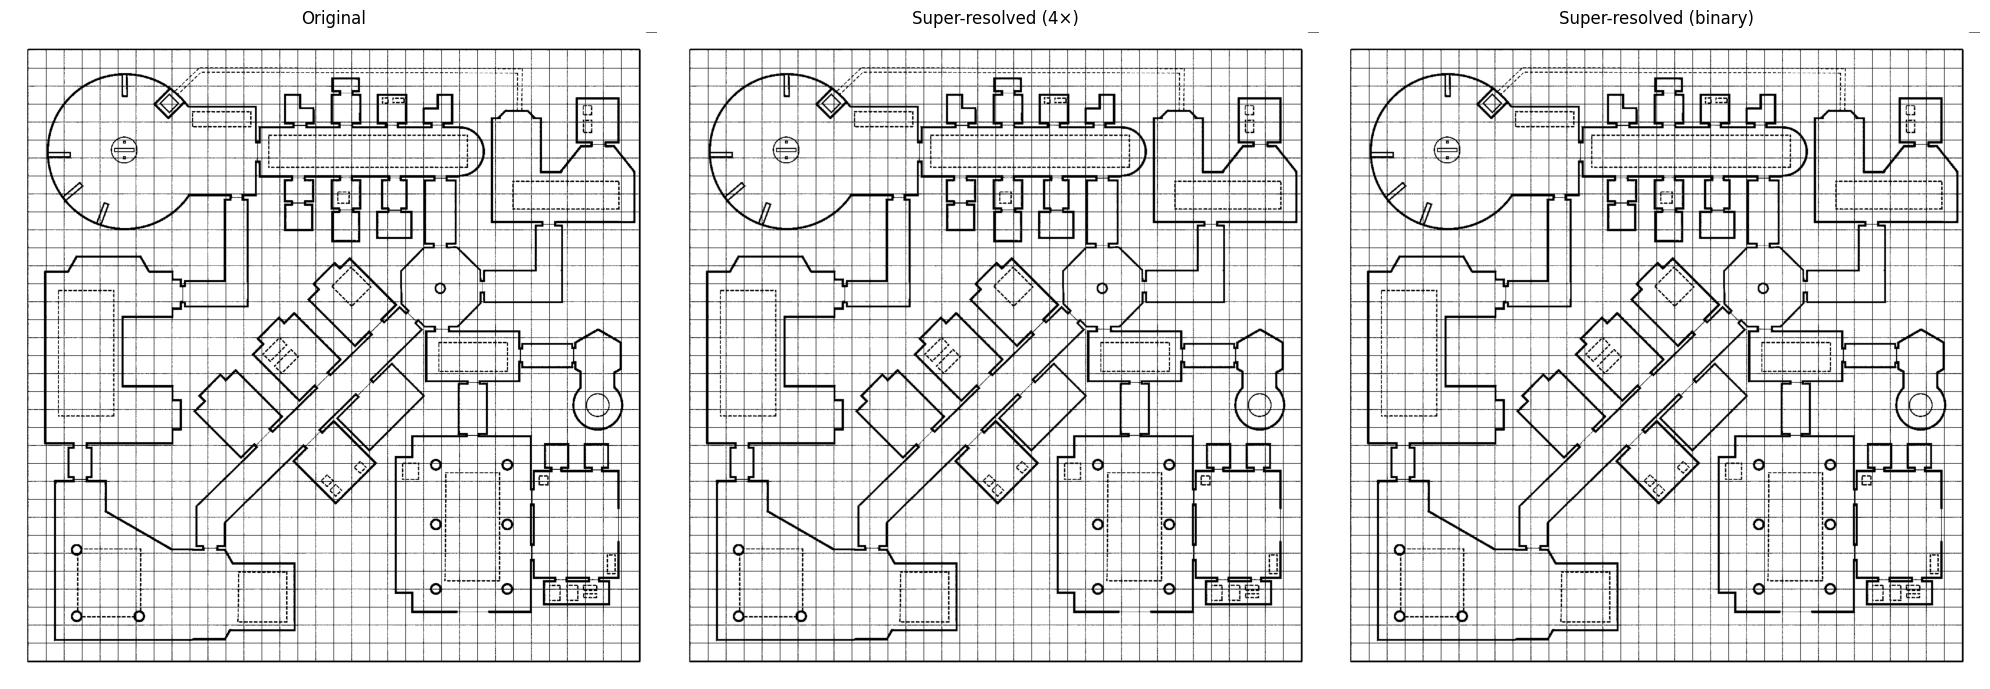

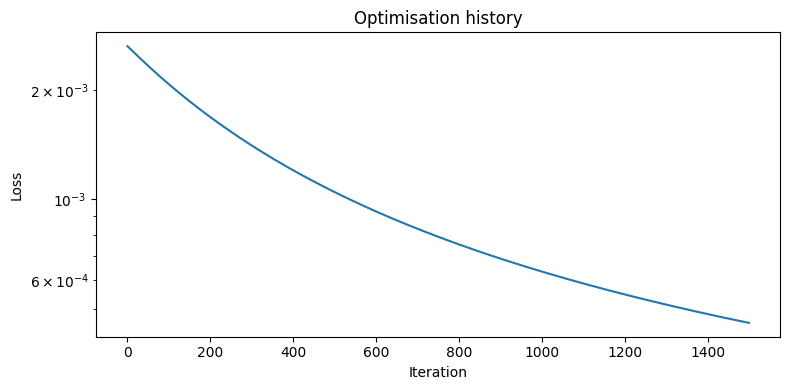

In [9]:
# ============================================================
# Visualisation
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

axes[0].imshow(binary, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original")

axes[1].imshow(result, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Super-resolved (4×)")

axes[2].imshow(binary_hr, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Super-resolved (binary)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig("super-res-map.png",dpi=300)
plt.show()

# Optimisation history
plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Optimisation history")
plt.yscale("log")
plt.tight_layout()
plt.show()

# inversion and binary closing


/tmp/ipykernel_3843082/3434394472.py:34: FutureWarning: `rectangle` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  lines_repaired = binary_closing(lines_clean, footprint=rectangle(1, 5))  # horizontal gaps
/tmp/ipykernel_3843082/3434394472.py:35: FutureWarning: `rectangle` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  lines_repaired = binary_closing(lines_repaired, footprint=rectangle(5, 1))  # vertical gaps


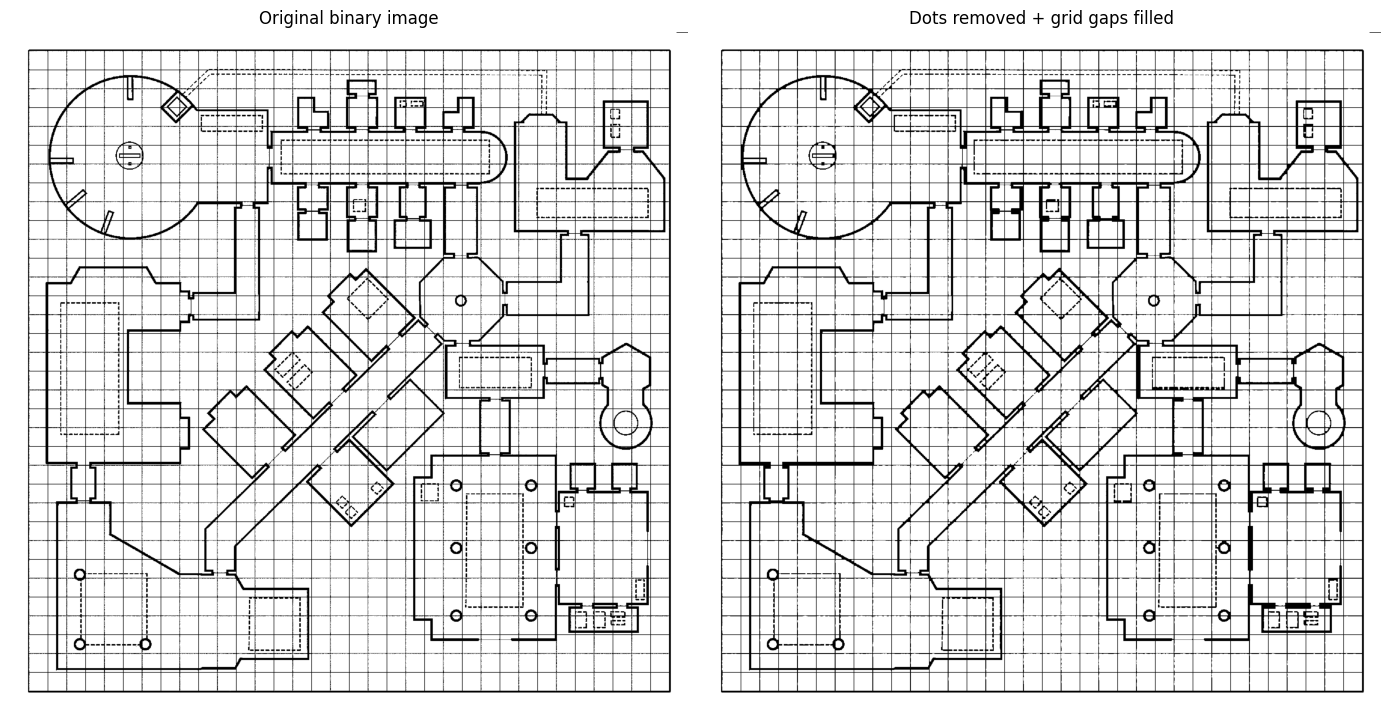

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import binary_closing, remove_small_objects, rectangle
from PIL import Image

station = io.imread("Armaros station.png").astype(np.float32)


# ------------------------------------------------------------
# Input: binary image with black lines on white background
# Can be shape (H, W) or (H, W, C)
# ------------------------------------------------------------
img = station[:, :, 0] if station.ndim == 3 else station

# If image is 0/255, threshold it
# Result: bw = True for white background, False for black lines
bw = img > 127 if img.max() > 1 else img > 0.5

# Invert so foreground = lines
# lines = True where black lines are
lines = ~bw

# ------------------------------------------------------------
# Step 1: remove tiny isolated dots / specks
# min_size may need tuning; try 3, 5, 8, 10
# ------------------------------------------------------------
lines_clean = remove_small_objects(lines, min_size=5)

# ------------------------------------------------------------
# Step 2: fill tiny gaps in horizontal and vertical grid lines
# These footprints bridge short 1-pixel or 2-pixel breaks
# without aggressively thickening the lines
# ------------------------------------------------------------
lines_repaired = binary_closing(lines_clean, footprint=rectangle(1, 5))  # horizontal gaps
lines_repaired = binary_closing(lines_repaired, footprint=rectangle(5, 1))  # vertical gaps

# If gaps are a bit larger, try:
# lines_repaired = binary_closing(lines_clean, footprint=rectangle(1, 5))
# lines_repaired = binary_closing(lines_repaired, footprint=rectangle(5, 1))

# ------------------------------------------------------------
# Convert back: black lines on white background
# ------------------------------------------------------------
result = ~lines_repaired
result_uint8 = (result.astype(np.uint8) * 255)

# Save
Image.fromarray(result_uint8).save("map_repaired.png")

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 8))

axes[0].imshow(bw, cmap="gray")
axes[0].set_title("Original binary image")

axes[1].imshow(result, cmap="gray")
axes[1].set_title("Dots removed + grid gaps filled")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig('inversion-closing.pdf',dpi=300)
plt.show()